# Motivation 1: ageing shrinks the feasible speed / DVFS configurations

**Message.** Ageing barely changes the energy a configuration costs per metre (< 1 %), but it shrinks
the energy the *same* BMS reading can deliver. For a charge-limited mission, the fastest feasible
configuration therefore drops with SOH, and a controller that ignores the long-term state picks a
configuration that the aged pack cannot finish above the SOC reserve.

**Setting** (identical to the `degradation` family of the benchmark, `envs/scenarios.py`): 5 km mission,
initial SOC fixed per workload complexity C so that energy-optimal driving at SOH 0.8 ends at the
reserve; SOH 1.0 / 0.9 / 0.8 (unknown to a BMS, which reports the same SOC for all three).

**Data.** Every point is a complete simulated mission in `RobotEnv` (test mode, ±20 % workload jitter)
at constant speed with the CPU at the controllers' QoS frequency (5 % QoS margin, 20 % complexity
allowance, as in `methods/baselines.py`). A configuration is *feasible* if the mission completes with
true SOC ≥ 0.05 (the reserve).

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve()
while not (REPO / 'envs').is_dir() and REPO != REPO.parent:   # notebook lives in <repo>/figures
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import envs  # noqa: F401  (sys.path for battery_model)
from envs.robot_env import RobotEnv, ECMParams, StressParams, throughput_freq_required, _voc
from envs.scenarios import build_suite
from envs.test_env import EVAL_CONFIG, make_robot

OUT = REPO / 'figures' / 'pdf'
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'STIXGeneral', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7.5,
    'axes.grid': True, 'grid.linestyle': '--', 'grid.linewidth': 0.4, 'grid.color': '#c8c8c8',
    'pdf.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
})

## Settings

In [2]:
SOHS = [1.00, 0.90, 0.80]
PANELS = {'(a) Low complexity': 1.0, '(b) Moderate complexity': 2.0}   # C = 3 is QoS-bound at 3.3 m/s
SPEEDS = np.round(np.arange(1.0, 5.0 + 1e-9, 0.05), 3)
L = 5000.0                                              # mission length [m]
SEED = 0
QOS_MARGIN = EVAL_CONFIG['baseline_qos_margin']         # 1.05
JITTER = EVAL_CONFIG['test_complexity_jitter']          # 0.2
SOC0 = {sc.tags['c']: sc.soc0 for sc in build_suite(['degradation'])}   # per complexity
RESERVE = make_robot(EVAL_CONFIG).soc_reserve
print('initial SOC per C:', {k: round(v, 4) for k, v in SOC0.items()}, '| reserve', RESERVE)

initial SOC per C: {1.0: 0.1871, 2.0: 0.1925, 3.0: 0.2093} | reserve 0.05


## Constant-configuration missions

In [3]:
def mission(v, c, soh, soc0, seed=SEED):
    """Full mission at constant speed v and the QoS frequency; None if QoS needs f > f_max."""
    rp = make_robot(dict(EVAL_CONFIG, mission_distance_m=L))
    rp.max_steps = 10**6
    f_req = throughput_freq_required(v, QOS_MARGIN * max(rp.qos_ref), (1 + JITTER) * c)
    if f_req > rp.f_max + 1e-12:
        return None
    f = float(np.clip(f_req, rp.f_min, rp.f_max))
    env = RobotEnv(robot=rp, ecm=ECMParams.default(rp), stress=StressParams(), soc_init=soc0,
                   soh_init=soh, complexity=c, mode='test', complexity_jitter=JITTER)
    env.reset(seed=seed)
    done = False
    while not done:
        _, _, term, trunc, _ = env.step([v, f])
        done = term or trunc
    completed = env.distance_m >= L - 1e-6
    return dict(freq=f, epd=env.total_energy_j / max(env.distance_m, 1e-9), completed=completed,
                soc_end=env.battery.soc, feasible=completed and env.battery.soc >= RESERVE)


def budget_per_m(soc0, soh):
    """Energy above the reserve per mission metre [J/m]; cell-side energy as the env counts it
    (OCV * I dt = Q_n * SOH * integral OCV(SOC, SOH) dSOC)."""
    rp = make_robot(EVAL_CONFIG)
    s = np.linspace(rp.soc_reserve, soc0, 400)
    return np.trapezoid([_voc(x, soh) for x in s], s) * rp.Q_n * soh / L


rows = []
for panel, c in PANELS.items():
    for soh in SOHS:
        for v in SPEEDS:
            m = mission(float(v), c, soh, SOC0[c])
            if m is not None:
                rows.append(dict(panel=panel, c=c, soh=soh, speed=float(v), **m))
data = pd.DataFrame(rows)
print(len(data), 'missions')

486 missions


## Fastest feasible configuration per SOH

In [4]:
summary = []
for (panel, soh), g in data.groupby(['panel', 'soh']):
    f = g[g.feasible]
    top = f.loc[f.speed.idxmax()]
    summary.append(dict(panel=panel, soh=soh, budget_J_per_m=budget_per_m(SOC0[PANELS[panel]], soh),
                        min_epd=g.epd.min(), v_feasible_min=f.speed.min(), v_feasible_max=top.speed,
                        freq_at_vmax=top.freq))
summary = pd.DataFrame(summary).sort_values(['panel', 'soh'], ascending=[True, False])
summary.round(3)

,panel,soh,budget_J_per_m,min_epd,v_feasible_min,v_feasible_max,freq_at_vmax
2,(a) Low complexity,1.0,6.837,5.190,1.70,5.00,1.440
1,(a) Low complexity,0.9,6.076,5.215,2.05,4.90,1.429
0,(a) Low complexity,0.8,5.367,5.241,2.80,3.80,1.310
5,(b) Moderate complexity,1.0,7.116,5.476,1.70,5.00,1.980
4,(b) Moderate complexity,0.9,6.325,5.502,2.05,4.60,1.894
3,(b) Moderate complexity,0.8,5.586,5.529,2.85,3.35,1.624


## Figure

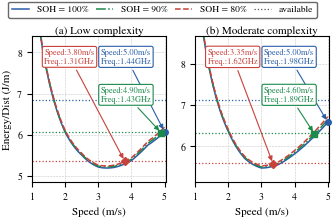

In [5]:
STYLE = {1.00: dict(color='#2a5ea8', ls='-',  marker='o', label='SOH = 100%'),
         0.90: dict(color='#1a8a4a', ls='-.', marker='s', label='SOH = 90%'),
         0.80: dict(color='#c8413b', ls='--', marker='D', label='SOH = 80%')}
BOX = {1.00: (0.70, 0.86), 0.90: (0.70, 0.60), 0.80: (0.28, 0.86)}   # annotation centres (axes fraction)

fig, axes = plt.subplots(1, 2, figsize=(3.6, 2.15))
for ax, (panel, c) in zip(axes, PANELS.items()):
    d = data[data.panel == panel]
    for soh in SOHS:
        s = STYLE[soh]
        g = d[d.soh == soh]
        ax.plot(g.speed, g.epd, color=s['color'], ls=s['ls'], lw=1.1, label=s['label'])
        ax.axhline(budget_per_m(SOC0[c], soh), color=s['color'], ls=':', lw=0.9)
    for soh in SOHS:
        s = STYLE[soh]
        o = summary[(summary.panel == panel) & (summary.soh == soh)].iloc[0]
        y = float(d[(d.soh == soh) & np.isclose(d.speed, o.v_feasible_max)].epd.iloc[0])
        ax.plot(o.v_feasible_max, y, marker=s['marker'], color=s['color'], ms=4, zorder=5, clip_on=False)
        ax.annotate(f'Speed:{o.v_feasible_max:.2f}m/s\nFreq.:{o.freq_at_vmax:.2f}GHz',
                    (o.v_feasible_max, y), xytext=BOX[soh], textcoords='axes fraction', fontsize=6.0,
                    color=s['color'], ha='center', va='center',
                    bbox=dict(boxstyle='round,pad=0.22', fc='white', ec=s['color'], lw=0.8),
                    arrowprops=dict(arrowstyle='-|>', color=s['color'], lw=0.8, mutation_scale=7))
    ax.set_title(panel, pad=2)
    ax.set_xlabel('Speed (m/s)')
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_xlim(1.0, 5.05)
    ax.set_ylim(d.epd.min() - 0.35, budget_per_m(SOC0[c], 1.0) + 1.55)
axes[0].set_ylabel('Energy/Dist (J/m)')
h, l = axes[0].get_legend_handles_labels()
h.append(plt.Line2D([], [], color='#555555', ls=':', lw=0.9))
l.append('available')
fig.legend(h, l, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.08), frameon=True,
           edgecolor='#444444', handlelength=1.8, columnspacing=0.8, fontsize=6.8)
fig.tight_layout(w_pad=0.5)
fig.savefig(OUT / 'motivation_1.pdf')
plt.show()

Solid / dashed curves: energy per metre a configuration costs (nearly identical for all SOH).
Dotted lines: energy per metre the pack holds above the reserve from the same BMS reading (falls with
SOH). Markers: fastest configuration that still ends above the reserve.

**Caption draft.** *Fig. 1. Aging effect on the feasible speed/frequency configurations for the same
BMS reading (5 km mission, charge-limited). Aging changes the energy per distance by less than 1 %,
but reduces the usable energy, so the fastest feasible configuration drops from 5.0 to 3.8 m/s (low
complexity) and from 5.0 to 3.3 m/s (moderate complexity).*

---
# Motivation 1b: the same ageing matters only when the charge is tight for the mission

**Message.** Both missions start from the same BMS reading, the charge-limited initial SOC of the
benchmark's `degradation` family for C = 2 (SOC 0.1925), at moderate complexity. On a 3 km mission
every configuration stays above the reserve at every SOH, so the long-term state is irrelevant. On a
5 km mission the aged pack no longer supports fast driving: the configuration an SOH-unaware
controller picks (BA-EPD, which believes SOH = 1) ends below the SOC reserve. Whether SOH matters thus
depends on the short-term state relative to the task (charge vs. mission energy). 3 km and 5 km are
mission lengths of the scenario suite (`switch` and `tight` / `degradation` families).

**Data.** *Energy needed*: complete simulated missions on the SOH 0.8 pack at constant speed and the
controllers' QoS frequency (energy per metre × mission length; runs that hit the SOC cutoff are
extrapolated from the distance covered). *Energy available*: cell-side energy above the reserve from
the initial SOC. *SOH-unaware choice*: median speed of BA-EPD (BMS observations + battery realism, as in
the benchmark) on the same mission at SOH 0.8, with its simulated end SOC.

In [6]:
from envs.scenarios import Scenario, make_env
from methods import BatteryAwareEPD

DISTANCES_KM = [3.0, 5.0]
C_DIST = 2.0
SOC_START = SOC0[C_DIST]           # benchmark degradation family, C = 2
SOH_TRUE = 0.8                      # pack the robot actually has
SOHS_B = [1.0, 0.9, 0.8]
SPEEDS_B = np.round(np.arange(1.5, 5.0 + 1e-9, 0.05), 3)
BMS = dict(EVAL_CONFIG, battery_obs='bms', battery_realism=True)


def energy_needed(v, dist_m, soh=SOH_TRUE, c=C_DIST, seed=SEED):
    """Mission energy [J] at constant speed v and the controllers' QoS frequency."""
    r = make_robot(dict(EVAL_CONFIG, mission_distance_m=dist_m))
    r.max_steps = 10**7
    f_req = throughput_freq_required(v, QOS_MARGIN * max(r.qos_ref), (1 + JITTER) * c)
    if f_req > r.f_max + 1e-12:
        return np.nan
    f = float(np.clip(f_req, r.f_min, r.f_max))
    env = RobotEnv(robot=r, ecm=ECMParams.default(r), stress=StressParams(), soc_init=SOC_START, soh_init=soh,
                   complexity=c, mode='test', complexity_jitter=JITTER)
    env.reset(seed=seed)
    done = False
    while not done:
        _, _, term, trunc, _ = env.step([v, f])
        done = term or trunc
    return env.total_energy_j / env.distance_m * dist_m


def energy_available(soc0, soh):
    """Cell-side energy above the reserve [J] from soc0."""
    r = make_robot(EVAL_CONFIG)
    s = np.linspace(r.soc_reserve, soc0, 600)
    return np.trapezoid([_voc(x, soh) for x in s], s) * r.Q_n * soh


def soh_unaware_run(dist_m, soh=SOH_TRUE, seed=3):
    """BA-EPD (SOC-aware, assumes SOH = 1) on the mission: median speed and true end SOC."""
    sc = Scenario('distance', f'L{dist_m:g}', dist_m, soh, SOC_START, C_DIST)
    env = make_env(BMS, sc)
    pol = BatteryAwareEPD(make_robot(BMS), BMS)
    obs, _ = env.reset(seed=BMS['seed'] + seed, options=sc.options())
    pol.reset()
    vs, done = [], False
    while not done:
        a = pol.select_action(obs)
        vs.append(float(a[0]))
        obs, _, term, trunc, info = env.step(a)
        done = term or trunc
    return float(np.median(vs)), float(info['soc']), env.distance_m >= dist_m - 1e-6


need = {km: np.array([energy_needed(float(v), km * 1e3) for v in SPEEDS_B]) / 1e3 for km in DISTANCES_KM}
avail = {h: energy_available(SOC_START, h) / 1e3 for h in SOHS_B}
unaware = {km: soh_unaware_run(km * 1e3) for km in DISTANCES_KM}

rows = []
for km in DISTANCES_KM:
    v_un, soc_end, done = unaware[km]
    e_un = float(np.interp(v_un, SPEEDS_B, need[km]))
    for h in SOHS_B:
        ok = need[km] <= avail[h]
        rows.append(dict(distance_km=km, soh=h, available_kJ=avail[h], needed_min_kJ=np.nanmin(need[km]),
                         v_max_feasible=SPEEDS_B[ok].max() if ok.any() else np.nan))
    rows.append(dict(distance_km=km, soh='BA-EPD @0.8', available_kJ=avail[SOH_TRUE], needed_min_kJ=e_un,
                     v_max_feasible=v_un, end_soc_true=soc_end, completed=done))
pd.DataFrame(rows).round(3)

,distance_km,soh,available_kJ,needed_min_kJ,v_max_feasible,end_soc_true,completed
0,3.0,1.0,35.580,16.585,5.00,NaN,NaN
1,3.0,0.9,31.623,16.585,5.00,NaN,NaN
2,3.0,0.8,27.932,16.585,5.00,NaN,NaN
3,3.0,BA-EPD @0.8,27.932,17.497,3.90,0.105,True
4,5.0,1.0,35.580,27.644,5.00,NaN,NaN
5,5.0,0.9,31.623,27.644,4.55,NaN,NaN
6,5.0,0.8,27.932,27.644,3.35,NaN,NaN
7,5.0,BA-EPD @0.8,27.932,29.176,3.90,0.043,True


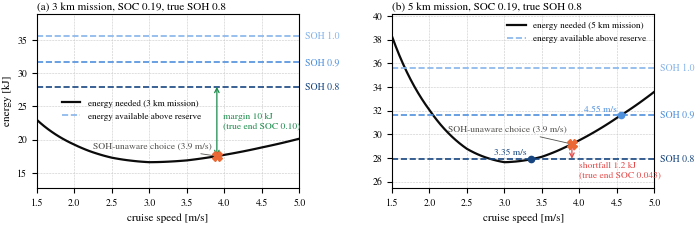

In [7]:
RAMP = {1.0: '#86b4ea', 0.9: '#4f90dd', 0.8: '#16457f'}
ORANGE, RED, INK = '#eb6834', '#e34948', '#0b0b0b'

fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.45))
for ax, km in zip(axes, DISTANCES_KM):
    e = need[km]
    ok_q = ~np.isnan(e)
    ax.plot(SPEEDS_B[ok_q], e[ok_q], color=INK, lw=1.6, label=f'energy needed ({km:g} km mission)')
    labels = []
    for h in SOHS_B:
        b = avail[h]
        ax.axhline(b, color=RAMP[h], lw=1.2, ls='--', label='energy available above reserve' if h == 1.0 else None)
        ax.text(5.07, b, f'SOH {h:.1f}', color=RAMP[h], fontsize=7, va='center', clip_on=False)
        feas = ok_q & (e <= b)
        if feas.any() and SPEEDS_B[feas].max() < SPEEDS_B.max() - 1e-9:
            vm = SPEEDS_B[feas].max()
            ax.plot([vm], [b], marker='o', color=RAMP[h], ms=4.5, zorder=5)
            labels.append((vm, b, h))
    v_un, soc_end, _ = unaware[km]
    e_un = float(np.interp(v_un, SPEEDS_B, e))
    b_true = avail[SOH_TRUE]
    ax.plot([v_un], [e_un], marker='X', color=ORANGE, ms=7, zorder=6)
    lo, hi = min(e[ok_q].min(), b_true), max(avail[1.0], e[ok_q].max())
    pad = 0.08 * (hi - lo)
    ax.set_ylim(lo - 2.6 * pad, hi + 2.2 * pad)
    dy = 0.012 * (hi - lo)
    for vm, b, h in labels:                    # max feasible speed, above-left of its marker
        ax.text(vm - 0.05, b + dy, f'{vm:.2f} m/s', color=RAMP[h], fontsize=6.8, ha='right', va='bottom')
    if e_un > b_true:
        ax.annotate('', xy=(v_un, b_true), xytext=(v_un, e_un),
                    arrowprops=dict(arrowstyle='<->', color=RED, lw=0.9, shrinkA=0, shrinkB=0))
        ax.text(v_un + 0.1, b_true - 2 * dy, f'shortfall {e_un - b_true:.1f} kJ\n(true end SOC {soc_end:.3f})',
                color=RED, fontsize=6.8, va='top')
        txt_xy = (2.25, e_un + 0.10 * (hi - lo))
    else:
        ax.annotate('', xy=(v_un, b_true), xytext=(v_un, e_un),
                    arrowprops=dict(arrowstyle='<->', color='#1a8a4a', lw=0.9, shrinkA=0, shrinkB=0))
        ax.text(v_un + 0.08, (b_true + e_un) / 2, f'margin {b_true - e_un:.0f} kJ\n(true end SOC {soc_end:.2f})',
                color='#1a8a4a', fontsize=6.8, va='center')
        txt_xy = (2.25, e_un + 0.06 * (hi - lo))
    ax.annotate(f'SOH-unaware choice ({v_un:.1f} m/s)', (v_un, e_un), xytext=txt_xy, fontsize=6.8,
                color='#52514e', arrowprops=dict(arrowstyle='-', color='#52514e', lw=0.6))
    ax.set_xlim(1.5, 5.0)
    ax.set_xlabel('cruise speed [m/s]')
    ax.set_title(f'({"ab"[DISTANCES_KM.index(km)]}) {km:g} km mission, SOC {SOC_START:.2f}, true SOH {SOH_TRUE:.1f}',
                 loc='left', pad=3)
    if km == DISTANCES_KM[0]:
        ax.legend(loc='center', bbox_to_anchor=(0.36, 0.45), fontsize=6.6, frameon=False)
    else:
        ax.legend(loc='upper right', fontsize=6.6, frameon=False)
axes[0].set_ylabel('energy [kJ]')
fig.tight_layout(w_pad=3.0)
fig.savefig(OUT / 'motivation_1_distance.pdf')
plt.show()

**Caption draft.** *Fig. X. Energy needed vs. energy available above the reserve from the same BMS reading
(SOC 0.19, C = 2) for a 3 km and a 5 km mission. For the shorter mission every configuration is feasible at
every SOH; for the 5 km mission the maximum feasible speed falls from 5.0 to about 3.3 m/s at SOH 0.8, and
the configuration chosen by an SOH-unaware controller (3.9 m/s) ends below the SOC reserve.*